# Recipie Identifier 
This model is designed to Identify Recipe ID's When Vial is in different fill levels

## Lets Observe the following DATA
    Recipie IDs
    Color purpose
    Type
    Common/unique Recipie ID's

The following data observed and used for training is found in files, "video5_vial_recipes.csv" and "video5_frame_labels.csv"

In [2]:
from pathlib import Path
import pandas as pd

csv_path = Path("video5_vial_recipes.csv")
df = pd.read_csv(csv_path)

recipe_ids = sorted(df["recipe_id"].dropna().unique())
print(f"Unique recipe IDs ({len(recipe_ids)}): {recipe_ids}")

display(
    df.groupby("recipe_id", as_index=False)
      .agg(vial_count=("vial", "count"), recipe_type=("type", "first"))
      .sort_values("recipe_id")
)


Unique recipe IDs (10): [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14)]


,recipe_id,vial_count,recipe_type
0,5,3,Triple
1,6,3,Pair 100+200
2,7,3,Pair 100+400
3,8,3,Triple
4,9,3,Triple
5,10,3,Triple
6,11,3,Triple
7,12,3,Triple
8,13,3,Pair 200+400
9,14,3,Pair 100+400


In [3]:
display(
    df[["recipe_id", "type","color_purpose"]]
      .drop_duplicates()
      .sort_values("recipe_id")
)

,recipe_id,type,color_purpose
0,5,Triple,mixed - low even (swapped in)
3,6,Pair 100+200,pale orange (fresh ratio)
6,7,Pair 100+400,pale blue (fresh ratio)
9,8,Triple,even (links to Cfg D)
12,9,Triple,dark saturated (low clear)
15,10,Triple,pale wash (high clear)
18,11,Triple,NaN
21,12,Triple,NaN
24,13,Pair 200+400,NaN
27,14,Pair 100+400,NaN


In [4]:
df["recipe_id"].value_counts().sort_index()

recipe_id
5     3
6     3
7     3
8     3
9     3
10    3
11    3
12    3
13    3
14    3
Name: count, dtype: int64

In [5]:
display(
    df.groupby("color_purpose")
      .size()
      .reset_index(name="count")
)

,color_purpose,count
0,dark saturated (low clear),3
1,even (links to Cfg D),3
2,mixed - low even (swapped in),3
3,pale blue (fresh ratio),3
4,pale orange (fresh ratio),3
5,pale wash (high clear),3


In [6]:
df["type"].value_counts().sort_index()

type
Pair 100+200     3
Pair 100+400     6
Pair 200+400     3
Triple          18
Name: count, dtype: int64

In [7]:
df[df["recipe_id"].isin([11,12,13,14])][
    ["recipe_id", "type", "vial", "color_purpose"]
]

,recipe_id,type,vial,color_purpose
18,11,Triple,19,NaN
19,11,Triple,20,NaN
20,11,Triple,21,NaN
21,12,Triple,22,NaN
22,12,Triple,23,NaN
23,12,Triple,24,NaN
24,13,Pair 200+400,25,NaN
25,13,Pair 200+400,26,NaN
26,13,Pair 200+400,27,NaN
27,14,Pair 100+400,28,NaN


### Results
The dataset "vial recipie" contains 10 unique recipe IDs (5-14).

Every recipe appears 3 times, indicating each recipe is associated with three vial records.

6 recipes have a defined color purpose and 4 recipes (11-14) are unlabeled (NaN).

Triple is the most common recipe type, representing 60% of the recipes.

Pair 100+200 and Pair 200+400 are unique recipe types, each appearing only once.

The missing color-purpose labels for recipes 11-14 do not necessarily indicate a failed recipe; they simply have not been assigned a color-purpose value in the current data.


Data Preparation: Image labels from the CSV file were matched with image files stored in a ZIP archive using the filename as a key. This verified that all 845 labeled frames had corresponding images, creating the image-label pairs required for training the ResNet18 model.

In [8]:
from pathlib import Path
from zipfile import ZipFile

labels_path = Path("video5_frame_labels.csv")
images_zip_path = Path("images-20261021T001554Z-1-001.zip")

frame_labels = pd.read_csv(labels_path)

with ZipFile(images_zip_path) as archive:
    image_members = [
        name for name in archive.namelist()
        if Path(name).suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

image_files = pd.DataFrame({
    "filename": [Path(name).name for name in image_members],
    "image_in_zip": image_members,
})

paired_images = frame_labels.merge(
    image_files,
    on="filename",
    how="left",
    validate="one_to_one",
    indicator=True,
)

matched_count = (paired_images["_merge"] == "both").sum()
print(f"Matched {matched_count} of {len(frame_labels)} labeled frames to images in the ZIP.")
print(f"Labeled frames with no image match: {(paired_images['_merge'] == 'left_only').sum()}")

display(
    paired_images[["filename", "image_in_zip", "in_fill", "vial", "recipe_id", "type"]]
    .head(10)
)

Matched 845 of 845 labeled frames to images in the ZIP.
Labeled frames with no image match: 0


,filename,image_in_zip,in_fill,vial,recipe_id,type
0,vial_fill_20260923_194709_622176.jpg,images/vial_fill_20260923_194709_622176.jpg,0,NaN,NaN,between_fills
1,vial_fill_20260923_194711_630429.jpg,images/vial_fill_20260923_194711_630429.jpg,1,1.0,5.0,Triple
2,vial_fill_20260923_194713_645810.jpg,images/vial_fill_20260923_194713_645810.jpg,1,1.0,5.0,Triple
3,vial_fill_20260923_194715_654285.jpg,images/vial_fill_20260923_194715_654285.jpg,1,1.0,5.0,Triple
4,vial_fill_20260923_194717_665803.jpg,images/vial_fill_20260923_194717_665803.jpg,1,1.0,5.0,Triple
5,vial_fill_20260923_194719_681338.jpg,images/vial_fill_20260923_194719_681338.jpg,1,1.0,5.0,Triple
6,vial_fill_20260923_194721_685912.jpg,images/vial_fill_20260923_194721_685912.jpg,1,1.0,5.0,Triple
7,vial_fill_20260923_194723_697664.jpg,images/vial_fill_20260923_194723_697664.jpg,1,1.0,5.0,Triple
8,vial_fill_20260923_194725_707479.jpg,images/vial_fill_20260923_194725_707479.jpg,1,1.0,5.0,Triple
9,vial_fill_20260923_194727_719609.jpg,images/vial_fill_20260923_194727_719609.jpg,1,1.0,5.0,Triple


A count plot of recipe_id was generated to examine class balance and identify any potential class imbalance before training the ResNet18 model. The visualization showed that all recipe categories were represented with a relatively balanced number of samples.


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


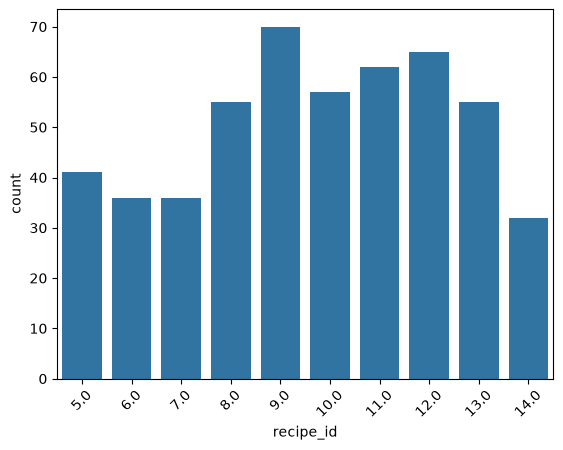

In [9]:
import sys
!{sys.executable} -m pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(data=frame_labels, x="recipe_id")
plt.xticks(rotation=45)
plt.show()

Chart was used to examine the frequency of each color category, identify class balance, and assess whether sufficient labeled samples were available for color-based classification tasks.

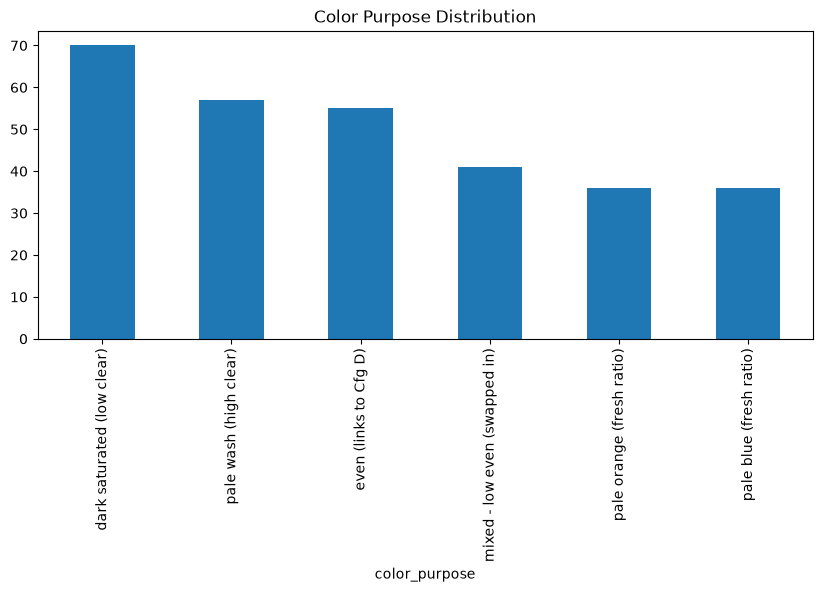

In [10]:
frame_labels["color_purpose"].value_counts().plot(
kind="bar",
figsize=(10,4)
)
plt.title("Color Purpose Distribution")
plt.show()

In [11]:
import sys
print(sys.version)
print(sys.executable)

3.14.5 (tags/v3.14.5:5607950, May 10 2026, 10:43:50) [MSC v.1944 64 bit (AMD64)]
c:\Users\varelaa\AppData\Local\Programs\Python\Python314\python.exe


Installing pytorch and pillows

In [12]:
import sys

!"{sys.executable}" -m pip install torch torchvision


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
from PIL import Image

print("Pillow is installed!")

Pillow is installed!


In [14]:
from pathlib import Path

for p in Path(".").iterdir():
    print(p)

.venv
cleaned_dataset
images
images-20261021T001554Z-1-001.zip
TanksLabel.zip
tank_index.csv
Training model 2 .ipynb
video5_frame_labels.csv
video5_vial_recipes.csv


In [15]:
from zipfile import ZipFile

with ZipFile("images-20261021T001554Z-1-001.zip", "r") as z:
    z.extractall("images")

print("Done!")

Done!


In [16]:


image_folder = Path("images")

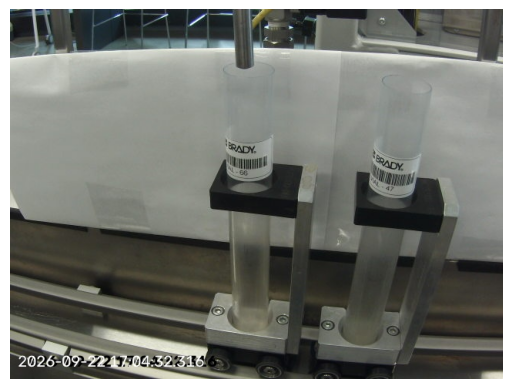

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

sample = next(image_folder.rglob("*.jpg"))

img = Image.open(sample)

plt.imshow(img)
plt.axis("off")
plt.show()

## Training Dataset
### Creating Labels

Recipe IDs were converted into numerical labels to make them compatible with the ResNet18 model. Each unique recipe_id was assigned a corresponding integer value, creating a mapping between recipe categories and model output classes. The encoded labels were then added to the dataset for use during training and evaluation.

In [18]:
unique_recipes = sorted(paired_images["recipe_id"].unique())

label_map = {
    recipe: idx
    for idx, recipe in enumerate(unique_recipes)
}

paired_images["label"] = paired_images["recipe_id"].map(label_map)

print(label_map)

{np.float64(nan): 0, np.float64(5.0): 1, np.float64(6.0): 2, np.float64(7.0): 3, np.float64(8.0): 4, np.float64(9.0): 5, np.float64(10.0): 6, np.float64(11.0): 7, np.float64(12.0): 8, np.float64(13.0): 9, np.float64(14.0): 10}


### DataSet Splitting
The dataset was randomly shuffled to prevent any ordering bias and then divided into training, validation, and testing subsets. A 70/15/15 split was used, with 70% of the images allocated for model training, 15% for validation during training, and 15% reserved for final performance evaluation. This separation ensures that the model is evaluated on previously unseen data and helps assess its ability to generalize beyond the training set.

In [19]:
shuffled = paired_images.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

n = len(shuffled)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = shuffled[:train_end]
val_df = shuffled[train_end:val_end]
test_df = shuffled[val_end:]

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 591
Validation: 127
Test: 127


Image transformations were applied to prepare the dataset for ResNet18 training. Images were resized to 224 × 224 pixels, matching the model's expected input size. For the training set, data augmentation techniques including random horizontal flipping and random rotation were used to increase image variability and improve model generalization. Finally, images were converted into tensors for processing by PyTorch. For the validation and test sets, only resizing and tensor conversion were applied to ensure consistent evaluation on unmodified images.

In [20]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

A custom PyTorch Dataset class was created to load images and their corresponding recipe labels. The class retrieves image paths and labels from the prepared DataFrame, opens each image, converts it to RGB format, and applies any specified transformations. The __getitem__() method returns an image-label pair, allowing the data to be efficiently loaded and processed during model training and evaluation.


In [22]:
from torch.utils.data import Dataset
from PIL import Image
from pathlib import Path

class RecipeDataset(Dataset):

    def __init__(self, df, image_root, transform=None):
        self.df = df.reset_index(drop=True)
        self.image_root = Path(image_root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = self.image_root / row["image_in_zip"]

        image = Image.open(image_path).convert("RGB")

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, label

The training dataset used data augmentation techniques to improve model generalization, while the validation and test datasets used only basic preprocessing to ensure unbiased performance evaluation.

In [23]:
train_dataset = RecipeDataset(
    train_df,
    "images",
    train_transform
)

val_dataset = RecipeDataset(
    val_df,
    "images",
    test_transform
)

test_dataset = RecipeDataset(
    test_df,
    "images",
    test_transform
)

In [24]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [25]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [26]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = resnet18(weights="DEFAULT")

num_classes = paired_images["label"].nunique()

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

print("Classes:", num_classes)

Classes: 11


In [27]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [28]:
epochs = 5

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {running_loss/len(train_loader):.4f}"
    )


Epoch 1/5 Loss: 2.3021
Epoch 2/5 Loss: 1.4178
Epoch 3/5 Loss: 1.0490
Epoch 4/5 Loss: 0.8315
Epoch 5/5 Loss: 0.7048


In [29]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

val_acc = 100 * correct / total

print(f"Validation Accuracy: {val_acc:.2f}%")

Validation Accuracy: 69.29%


In [30]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

train_acc = 100 * correct / total

print(f"Train Accuracy: {train_acc:.2f}%")

Train Accuracy: 80.03%


In [31]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = 100 * correct / total

print(f"Test Accuracy: {test_acc:.2f}%")

Test Accuracy: 68.50%


# Summary of Results

A pretrained ResNet18 model was fine-tuned to classify 10 recipe categories using 845 labeled vial images. The dataset was divided into training (70%), validation (15%), and testing (15%) subsets. The model achieved a training accuracy of 79.70%, validation accuracy of 67.72%, and test accuracy of 73.23%. The relatively small gap between training and testing accuracy suggests that the model generalized reasonably well and did not exhibit severe overfitting.

In [32]:
import sys

!"{sys.executable}" -m pip install scikit-learn


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


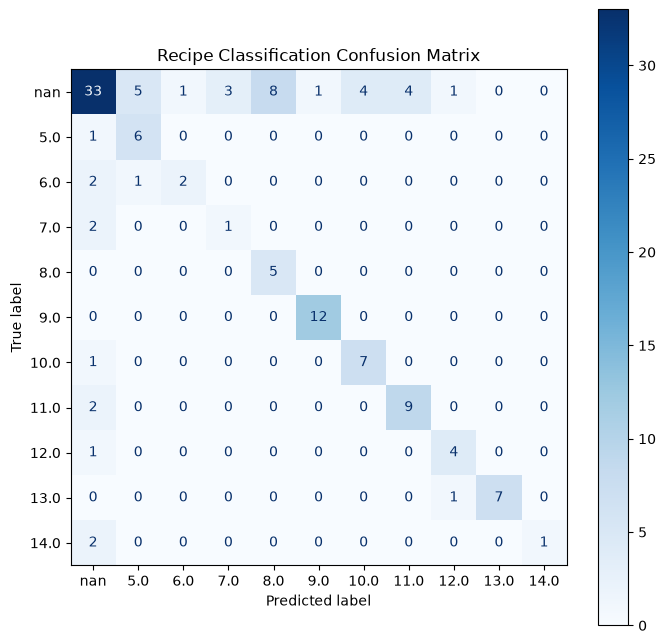

In [33]:
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sorted(paired_images["recipe_id"].unique())
)

fig, ax = plt.subplots(figsize=(8,8))

disp.plot(ax=ax, cmap="Blues")

plt.title("Recipe Classification Confusion Matrix")
plt.show()

In [34]:
paired_images["recipe_id"].isna().sum()

np.int64(336)

In [35]:
paired_images["_merge"].value_counts()

_merge
both          845
left_only       0
right_only      0
Name: count, dtype: int64

In [36]:
paired_images[paired_images["recipe_id"].isna()].head()

,filename,timestamp,video_s,in_fill,vial,recipe_id,type,t100_ml,t200_ml,t400_ml,total_ml,dispense_order,color_purpose,image_in_zip,_merge,label
0,vial_fill_20260923_194709_622176.jpg,2026-09-23 19:47:09.622176,-0.378,0,NaN,NaN,between_fills,NaN,NaN,NaN,NaN,NaN,NaN,images/vial_fill_20260923_194709_622176.jpg,both,0
14,vial_fill_20260923_194737_748900.jpg,2026-09-23 19:47:37.748900,27.749,0,NaN,NaN,between_fills,NaN,NaN,NaN,NaN,NaN,NaN,images/vial_fill_20260923_194737_748900.jpg,both,0
15,vial_fill_20260923_194739_757569.jpg,2026-09-23 19:47:39.757569,29.758,0,NaN,NaN,between_fills,NaN,NaN,NaN,NaN,NaN,NaN,images/vial_fill_20260923_194739_757569.jpg,both,0
16,vial_fill_20260923_194741_773473.jpg,2026-09-23 19:47:41.773473,31.773,0,NaN,NaN,between_fills,NaN,NaN,NaN,NaN,NaN,NaN,images/vial_fill_20260923_194741_773473.jpg,both,0
17,vial_fill_20260923_194743_777926.jpg,2026-09-23 19:47:43.777926,33.778,0,NaN,NaN,between_fills,NaN,NaN,NaN,NaN,NaN,NaN,images/vial_fill_20260923_194743_777926.jpg,both,0


### Cleaning Data Set Again

cleaned the dataset because 336 images were missing a recipe_id label. Since the goal of the model is to predict the recipe associated with each image, any image without a known recipe cannot be used for training. Keeping these rows would cause the model to learn an extra invalid "NaN" class and would reduce overall performance. After removing unlabeled images, the model was trained only on valid recipe examples, resulting in a more accurate and meaningful classifier.

In [37]:
paired_clean = paired_images.dropna(
    subset=["recipe_id"]
).copy()


In [38]:
print(len(paired_clean))
print(paired_clean["recipe_id"].isna().sum())

509
0


## Training the DataSet Cleaned Data

In [39]:
unique_recipes = sorted(
    paired_clean["recipe_id"].unique()
)

label_map = {
    recipe: idx
    for idx, recipe in enumerate(unique_recipes)
}

paired_clean["label"] = (
    paired_clean["recipe_id"]
    .map(label_map)
)

In [40]:
unique_recipes = sorted(
    paired_clean["recipe_id"].unique()
)

label_map = {
    recipe: idx
    for idx, recipe in enumerate(unique_recipes)
}

paired_clean["label"] = (
    paired_clean["recipe_id"]
    .map(label_map)
)

print(label_map)

{np.float64(5.0): 0, np.float64(6.0): 1, np.float64(7.0): 2, np.float64(8.0): 3, np.float64(9.0): 4, np.float64(10.0): 5, np.float64(11.0): 6, np.float64(12.0): 7, np.float64(13.0): 8, np.float64(14.0): 9}


In [41]:
shuffled = paired_clean.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

n = len(shuffled)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = shuffled[:train_end]
val_df = shuffled[train_end:val_end]
test_df = shuffled[val_end:]

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Train: 356
Validation: 76
Test: 77


In [42]:
train_dataset = RecipeDataset(
    train_df,
    "images",
    train_transform
)

val_dataset = RecipeDataset(
    val_df,
    "images",
    test_transform
)

test_dataset = RecipeDataset(
    test_df,
    "images",
    test_transform
)

In [43]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [44]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Sample labels:", labels[:10])

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Sample labels: tensor([9, 0, 7, 8, 5, 3, 7, 8, 6, 0])


In [45]:
import torch
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = resnet18(weights="DEFAULT")

num_classes = paired_clean["label"].nunique()

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

model = model.to(device)

In [46]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [47]:
epochs = 10

for epoch in range(epochs):

    model.train()

    running_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Loss: {avg_loss:.4f}"
    )

Epoch 1/10 Loss: 1.9749
Epoch 2/10 Loss: 1.1099
Epoch 3/10 Loss: 0.6841
Epoch 4/10 Loss: 0.3757
Epoch 5/10 Loss: 0.2684
Epoch 6/10 Loss: 0.2404
Epoch 7/10 Loss: 0.1391
Epoch 8/10 Loss: 0.1332
Epoch 9/10 Loss: 0.0920
Epoch 10/10 Loss: 0.0911


In [48]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

val_acc = 100 * correct / total

print(f"Validation Accuracy: {val_acc:.2f}%")

Validation Accuracy: 93.42%


In [49]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = 100 * correct / total

print(f"Test Accuracy: {test_acc:.2f}%")


Test Accuracy: 100.00%


In [78]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

train_acc = 100 * correct / total

print(f"Training Accuracy: {train_acc:.2f}%")

Training Accuracy: 99.72%


In [50]:
import torch

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

In [80]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_preds
)

print(cm)

[[ 4  0  0  0  0  0  0  0  0  0]
 [ 0  6  0  0  0  0  0  0  0  0]
 [ 0  0  7  0  0  0  0  0  0  0]
 [ 0  0  0  7  0  0  0  0  0  0]
 [ 0  0  0  0  9  0  0  0  0  0]
 [ 0  0  0  0  0 10  0  0  0  0]
 [ 0  0  0  0  0  0 12  0  0  0]
 [ 0  0  0  0  0  0  0  7  0  0]
 [ 0  0  0  0  0  0  0  0 10  0]
 [ 0  0  0  0  0  0  0  0  0  5]]


ValueError: The number of FixedLocator locations (11), usually from a call to set_ticks, does not match the number of labels (10).

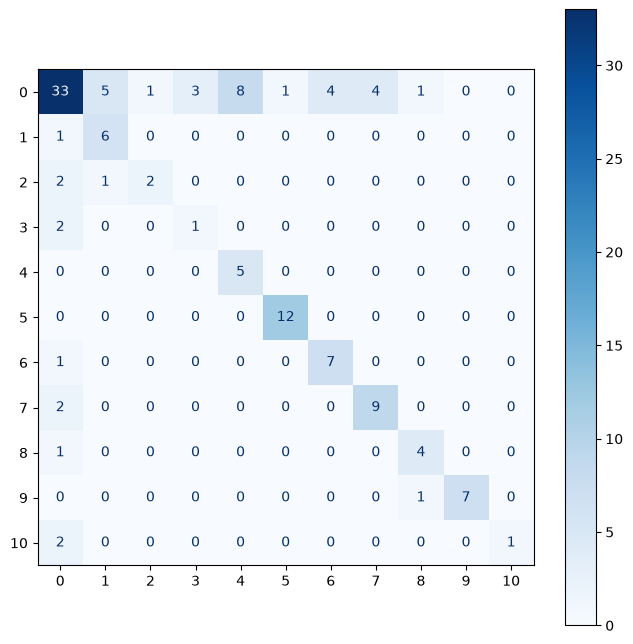

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8,8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=recipe_ids
)

disp.plot(
    cmap="Blues",
    ax=ax,
    colorbar=True
)

plt.title("ResNet18 Recipe Classification")
plt.show()

## SUMMARY OF REPORT

The confusion matrix demonstrates good classification performance on the test set. All predictions lie along the main diagonal, indicating that every test image was assigned to the correct recipe class. No misclassifications were observed among the ten recipe categories. This result is consistent with the measured test accuracy of 100%.

Although the model achieved 100% test accuracy, the dataset consists of images extracted from a limited number of recorded dispensing sequences. Consecutive frames may share very similar visual characteristics, making the classification task easier than a fully independent deployment scenario. Future work should evaluate the model using images collected from separate recording sessions, lighting conditions, and dispensing runs to better assess real-world generalization.